In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("../data/yelp_sample_1000.csv")

print(df.shape)

(1000, 3)


In [3]:
from transformers import AutoTokenizer

In [4]:
model_a = "nlptown/bert-base-multilingual-uncased-sentiment"
model_b = "typeform/distilbert-base-uncased-mnli"

tokenizer_a = AutoTokenizer.from_pretrained(model_a)
tokenizer_b = AutoTokenizer.from_pretrained(model_b)

In [16]:
print("Ozellik :" , "Tokenizer A" , "Tokenizer B")
print("*" * 50)
print(f"Model :	BERT Multilingual ,    DistilBERT")
print(f"Vocabulary Size :{tokenizer_a.vocab_size} ,    {tokenizer_b.vocab_size}")
print(f"Model Max Length :{tokenizer_a.model_max_length} ,    {tokenizer_b.model_max_length}")
print(f"PAD Token :{tokenizer_a.pad_token} ,    {tokenizer_b.pad_token}")
print(f"UNK Token :{tokenizer_a.unk_token} ,    {tokenizer_b.unk_token}")
print(f"CLS Token :{tokenizer_a.cls_token} ,    {tokenizer_b.cls_token}")
print(f"SEP Token :{tokenizer_a.sep_token} ,    {tokenizer_b.sep_token}")



Ozellik : Tokenizer A Tokenizer B
**************************************************
Model :	BERT Multilingual ,    DistilBERT
Vocabulary Size :105879 ,    30522
Model Max Length :512 ,    512
PAD Token :[PAD] ,    [PAD]
UNK Token :[UNK] ,    [UNK]
CLS Token :[CLS] ,    [CLS]
SEP Token :[SEP] ,    [SEP]


In [19]:
text = "The restaurant was unbelievably disappointing."

tokens_a = tokenizer_a.tokenize(text)

print(tokens_a)
print("Token A Boyutu :" , len(tokens_a))
print("*" * 50)
 
tokens_b = tokenizer_b.tokenize(text)

print(tokens_b)
print("Token B Boyutu :" , len(tokens_b))

['the', 'restaurant', 'was', 'un', '##beli', '##eva', '##bly', 'disa', '##ppo', '##inti', '##ng', '.']
Token A Boyutu : 12
**************************************************
['the', 'restaurant', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'disappointing', '.']
Token B Boyutu : 10


In [23]:
encoded = tokenizer_a(
    text,
    add_special_tokens=True
)

print(encoded["input_ids"])
print("Uzunluk " , len(encoded["input_ids"]))

encoded_B = tokenizer_b(
    text , 
    add_special_tokens = True
)
print(encoded_B["input_ids"])
print("Uzunluk " , len(encoded_B["input_ids"]))


[101, 10103, 21688, 10140, 10119, 27224, 16877, 28634, 31021, 54894, 36592, 10422, 119, 102]
Uzunluk  14
[101, 1996, 4825, 2001, 4895, 8671, 2666, 3567, 6321, 15640, 1012, 102]
Uzunluk  12


In [24]:
texts = df["text"].tolist()

In [39]:
encoded_texts_A = [tokenizer_a(text, truncation=False) for text in texts]

lens = [len(encoded["input_ids"]) for encoded in encoded_texts_A]

df["tokens_a"] = lens


encoded_texts_B = [tokenizer_b(text, truncation=False) for text in texts]

lens_b = [len(encoded["input_ids"]) for encoded in encoded_texts_B]

df["tokens_b"] = lens_b

print(df[["tokens_a", "tokens_b"]].head())

   tokens_a  tokens_b
0       363       354
1        22        19
2       140       138
3        15        14
4        95        89


In [44]:
df[["tokens_a" , "tokens_b"]].describe([0 , 0.05 ,0.25 , 0.50 ,0.75, 0.90 ,0.95 , 0.99 ,1]).T

,count,mean,std,min,0%,5%,25%,50%,75%,90%,95%,99%,100%,max
tokens_a,1000.0,184.500,165.667220,5.0,5.0,26.0,71.00,137.0,243.25,383.0,500.15,858.0,1230.0,1230.0
tokens_b,1000.0,175.475,157.333064,5.0,5.0,25.0,66.75,130.5,230.25,367.4,467.15,801.2,1163.0,1163.0


In [45]:
df["word_count"] = df["text"].str.split().str.len()

print(df[["word_count", "tokens_a", "tokens_b"]].mean())

word_count    131.200
tokens_a      184.500
tokens_b      175.475
dtype: float64


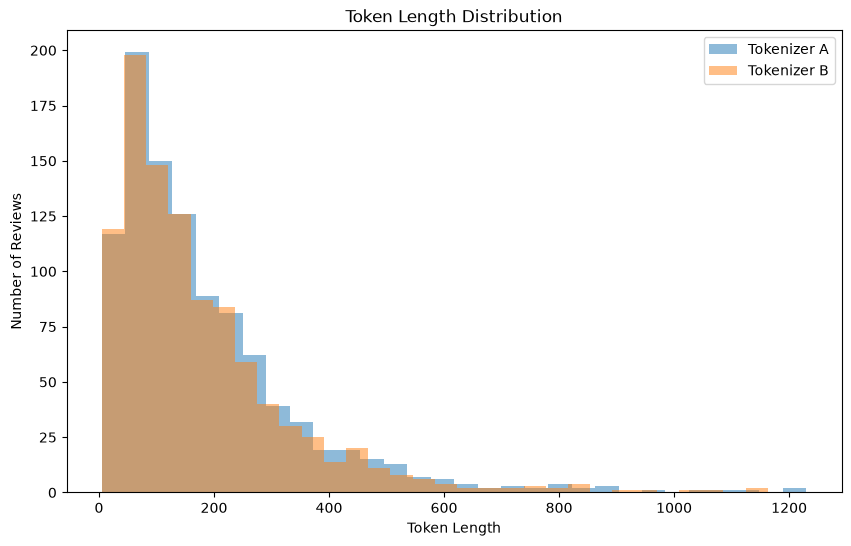

In [55]:
plt.figure(figsize=(10, 6))
plt.hist(df["tokens_a"], alpha=0.5, bins=30, label="Tokenizer A")
plt.hist(df["tokens_b"], alpha=0.5, bins=30, label="Tokenizer B")
plt.xlabel("Token Length")
plt.ylabel("Number of Reviews")
plt.title("Token Length Distribution")
plt.legend()
plt.show()

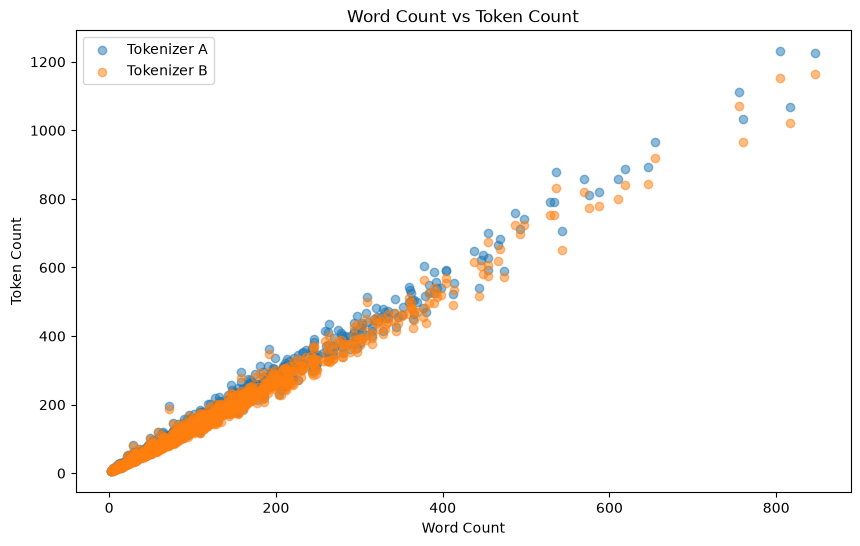

In [59]:
plt.figure(figsize=(10, 6))
plt.scatter(data=df , x="word_count" ,y="tokens_a" , alpha=0.5, label="Tokenizer A")
plt.scatter(data=df , x="word_count" ,y="tokens_b" , alpha=0.5, label="Tokenizer B")
plt.xlabel("Word Count")
plt.ylabel("Token Count")
plt.title("Word Count vs Token Count")
plt.legend()
plt.show()

In [70]:
short_text = df.loc[df["tokens_a"] < 50, "text"].iloc[0]

medium_text = df.loc[
    (df["tokens_a"] >= 100) & (df["tokens_a"] <= 200),
    "text"
].iloc[0]

long_text = df.loc[df["tokens_a"] > 512, "text"].iloc[0]

print("Model A\n")
print("Orjinal")

print("Short A:", len(tokenizer_a(short_text)["input_ids"]))
print("Medium A:", len(tokenizer_a(medium_text)["input_ids"]))
print("Long A:", len(tokenizer_a(long_text, truncation=False)["input_ids"]))

print("*" * 50)
print("128 Sonrasi")

print("Short A:", len(tokenizer_a(short_text , truncation=True , max_length=128)["input_ids"]))
print("Medium A:", len(tokenizer_a(medium_text, truncation=True , max_length=128)["input_ids"]))
print("Long A:", len(tokenizer_a(long_text, truncation=True , max_length=128)["input_ids"]))


print("\nModel B\n")
print("Orjinal")
print("Short B:", len(tokenizer_b(short_text, truncation=False)["input_ids"]))
print("Medium B:", len(tokenizer_b(medium_text, truncation=False )["input_ids"]))
print("Long B:", len(tokenizer_b(long_text, truncation=False)["input_ids"]))

print("*" * 50)
print("128 Sonrasi")

print("Short A:", len(tokenizer_b(short_text , truncation=True , max_length=128)["input_ids"]))
print("Medium A:", len(tokenizer_b(medium_text, truncation=True , max_length=128)["input_ids"]))
print("Long A:", len(tokenizer_b(long_text, truncation=True , max_length=128)["input_ids"]))


Model A

Orjinal
Short A: 22
Medium A: 140
Long A: 525
**************************************************
128 Sonrasi
Short A: 22
Medium A: 128
Long A: 128

Model B

Orjinal
Short B: 19
Medium B: 138
Long B: 498
**************************************************
128 Sonrasi
Short A: 19
Medium A: 128
Long A: 128


In [80]:
max_lengths = [128, 256]

for max_len in max_lengths:
    print("Token sınırı:", max_len)
    print("\nTokenizer A:", (df["tokens_a"] > max_len).sum())
    lost_tokens_A = (df["tokens_a"] - max_len).clip(lower=0)
    print("Lost Token A:", lost_tokens_A.mean())
    print("\nTokenizer B:", (df["tokens_b"] > max_len).sum())
    lost_tokens_B = (df["tokens_b"] - max_len).clip(lower=0)
    print("Lost Token B:", lost_tokens_B.mean())
    print("-" * 30)

Token sınırı: 128

Tokenizer A: 532
Lost Token A: 83.956

Tokenizer B: 509
Lost Token B: 76.647
------------------------------
Token sınırı: 256

Tokenizer A: 227
Lost Token A: 37.77

Tokenizer B: 206
Lost Token B: 33.101
------------------------------


In [92]:
encoded_a = tokenizer_a(
    short_text,
    truncation=True,
    max_length=128,
    padding="max_length",
    return_attention_mask=True
)

for token_id, mask in zip(encoded_a["input_ids"], encoded_a["attention_mask"]):
    if mask == 0:
        assert token_id == tokenizer_a.pad_token_id
    else:
        assert token_id != tokenizer_a.pad_token_id


print("Tokenizer A\n")
print("Input IDs Length:", len(encoded_a["input_ids"]))
print("Attention Mask Length:", len(encoded_a["attention_mask"]))

print("Gerçek Token:", sum(encoded_a["attention_mask"]))
print("Padding Token:", encoded_a["attention_mask"].count(0))


print("*" * 50)
encoded_b = tokenizer_b(
    short_text,
    truncation=True,
    max_length=128,
    padding="max_length",
    return_attention_mask=True
)



for token_id, mask in zip(encoded_b["input_ids"], encoded_b["attention_mask"]):
    if mask == 0:
        assert token_id == tokenizer_b.pad_token_id
    else:
        assert token_id != tokenizer_b.pad_token_id



print("Tokenizer B\n")
print("Input IDs Length:", len(encoded_b["input_ids"]))
print("Attention Mask Length:", len(encoded_b["attention_mask"]))

print("Gerçek Token:", sum(encoded_b["attention_mask"]))
print("Padding Token:", encoded_b["attention_mask"].count(0))

Tokenizer A

Input IDs Length: 128
Attention Mask Length: 128
Gerçek Token: 22
Padding Token: 106
**************************************************
Tokenizer B

Input IDs Length: 128
Attention Mask Length: 128
Gerçek Token: 19
Padding Token: 109


| Özellik | 128 Token | 256 Token |
|---|---|---|
| Maksimum giriş tokenı | 128 | 256 |
| Attention skor matrisi | 128 × 128 | 256 × 256 |
| Matris eleman sayısı | 16.384 | 65.536 |
| Truncation riski | Daha yüksek | Daha düşük |
| Padding miktarı (Fixed Padding) | Daha az | Daha fazla |
| Teorik Attention maliyeti | **1×** | **4×** |